# Oasis Infobyte – Data Science Internship

**Student Name:** Bhushan Hiralal Patel

**Track:** Data Science

**Task 1:**   Iris Flower Classification


Iris Flower Classification Using Machine Learning
Oasis Infobyte – Data Science Internship

Objective

To develop a machine learning model that predicts the species of an Iris flower based on its sepal and petal measurements. Logistic Regression and KNN algorithms are used and compared to determine the better-performing model.

In [1]:
# Import the required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Iris dataset

iris = load_iris()

# Display the dataset description
print(iris.DESCR[:1000])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [3]:
# Convert dataset into a DataFrame

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the flower species as a target column
df["species"] = iris.target

# Replace numerical labels with species names
df["species"] = df["species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


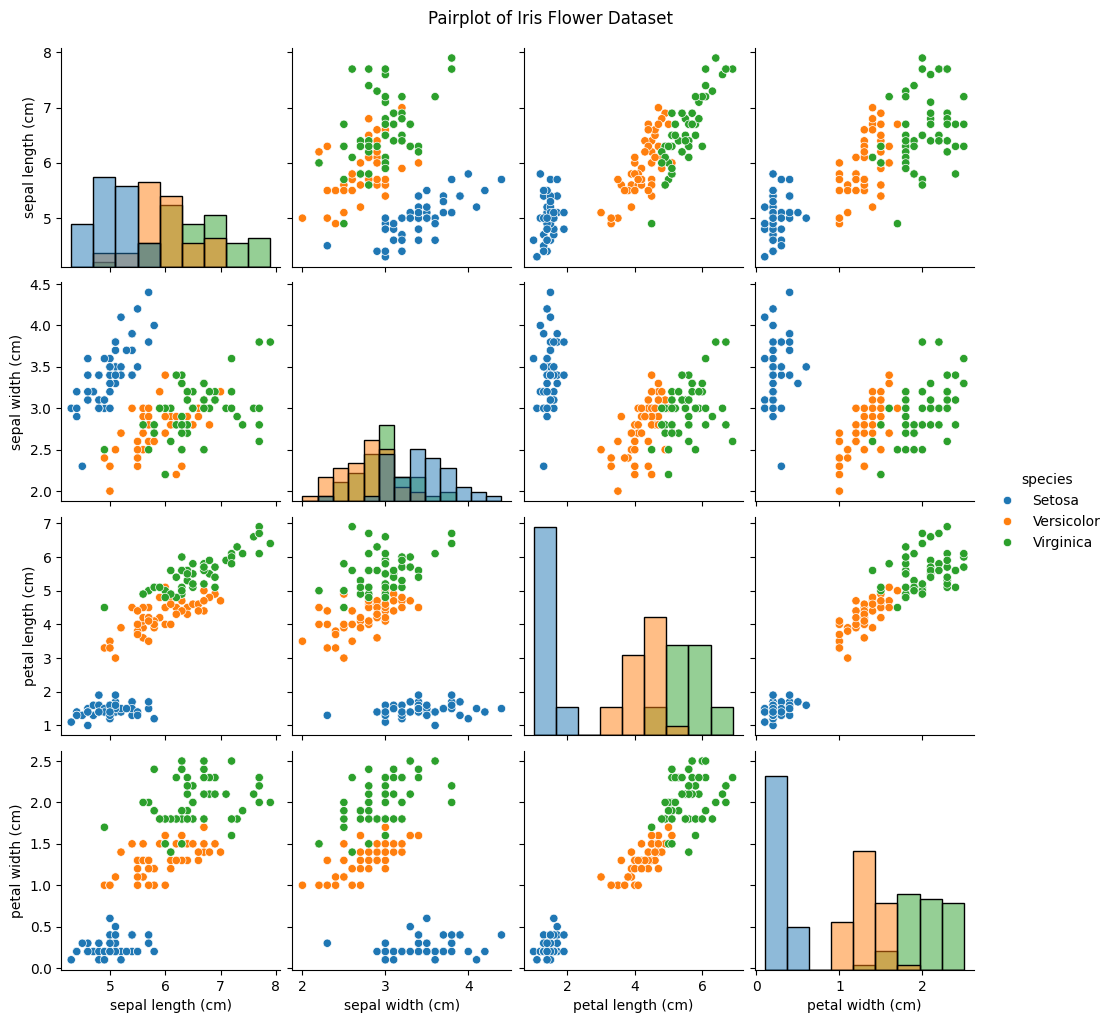

In [7]:
# Create a pairplot

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Flower Dataset", y=1.02)

plt.show()

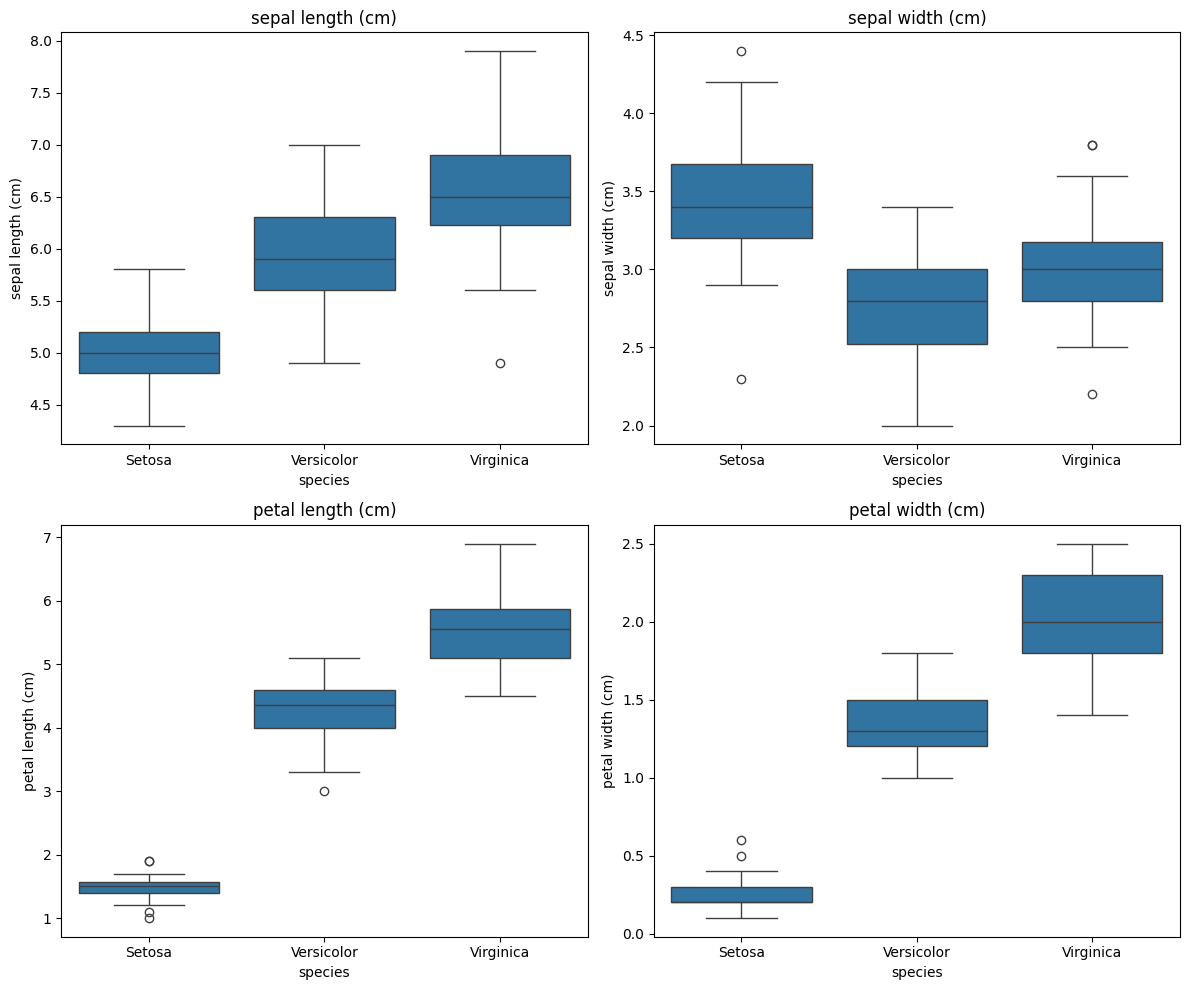

In [8]:
# Create boxplots for all four features

features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

plt.figure(figsize=(12, 10))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(
        data=df,
        x="species",
        y=feature
    )

    plt.title(feature)

plt.tight_layout()
plt.show()

### Feature Selection Discussion

The Iris dataset contains four important features: sepal length, sepal width, petal length, and petal width.

From the pairplot and boxplots, we can observe that petal length and petal width are the most useful features for distinguishing the three Iris flower species.

Setosa is clearly separated from the other species based on petal measurements. However, Versicolor and Virginica show some overlap.

Therefore, petal length and petal width are considered the most discriminative features for this classification problem. All four features will be used to train our models.

In [9]:
# Separate input features and target

X = df.drop("species", axis=1)

y = df["species"]

# Display their shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [10]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [11]:
print("Training species distribution:")
print(y_train.value_counts())

print("\nTesting species distribution:")
print(y_test.value_counts())

Training species distribution:
species
Setosa        40
Virginica     40
Versicolor    40
Name: count, dtype: int64

Testing species distribution:
species
Setosa        10
Virginica     10
Versicolor    10
Name: count, dtype: int64


In [12]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

In [13]:
# Create Logistic Regression model

lr_model = LogisticRegression(max_iter=200)

# Train the model

lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [14]:
# Import K-Nearest Neighbours

from sklearn.neighbors import KNeighborsClassifier

In [15]:
# Import required tools

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create KNN model with feature scaling

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model

knn_model.fit(X_train, y_train)

print("Scaled KNN model trained successfully!")

Scaled KNN model trained successfully!


In [16]:
# Make predictions using Logistic Regression

lr_predictions = lr_model.predict(X_test)

# Make predictions using KNN

knn_predictions = knn_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [17]:
# Display actual and predicted values

comparison = pd.DataFrame({
    "Actual Species": y_test.values,
    "Logistic Regression": lr_predictions,
    "KNN": knn_predictions
})

comparison.head(10)

,Actual Species,Logistic Regression,KNN
0,Setosa,Setosa,Setosa
1,Virginica,Virginica,Virginica
2,Versicolor,Versicolor,Versicolor
3,Versicolor,Versicolor,Versicolor
4,Setosa,Setosa,Setosa
5,Versicolor,Versicolor,Versicolor
6,Setosa,Setosa,Setosa
7,Setosa,Setosa,Setosa
8,Virginica,Virginica,Virginica
9,Versicolor,Versicolor,Versicolor


In [18]:
# Import accuracy_score

from sklearn.metrics import accuracy_score

# Calculate accuracy

lr_accuracy = accuracy_score(y_test, lr_predictions)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 96.67 %
KNN Accuracy: 93.33 %


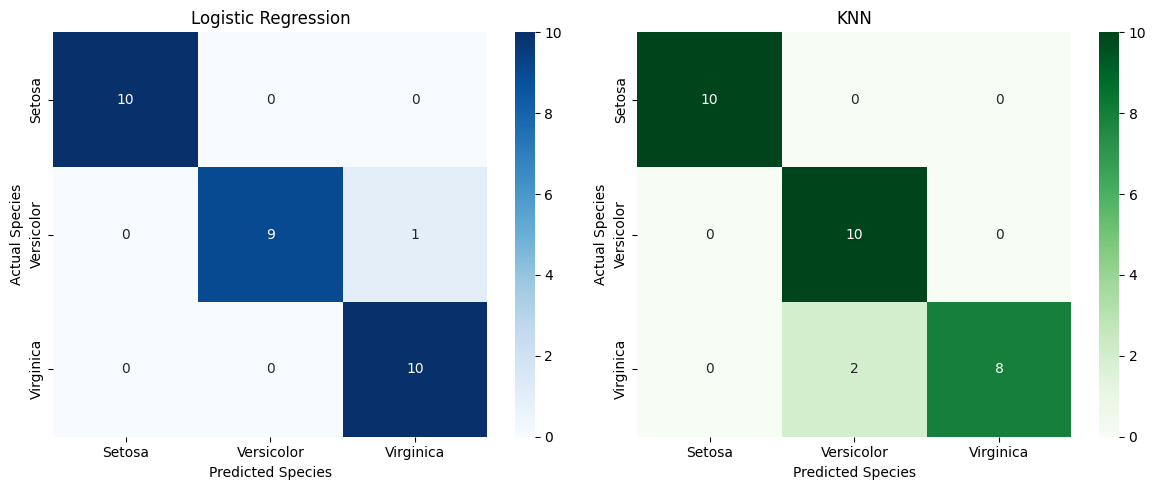

In [19]:
# Import confusion matrix

from sklearn.metrics import confusion_matrix

# Define species order

species_names = ["Setosa", "Versicolor", "Virginica"]

# Logistic Regression confusion matrix

lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=species_names
)

# KNN confusion matrix

knn_cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=species_names
)

# Plot both confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[1]
)

axes[1].set_title("KNN")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

In [20]:
# Import classification_report

from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, lr_predictions))

print("\nKNN CLASSIFICATION REPORT")
print(classification_report(y_test, knn_predictions))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      0.90      0.95        10
   Virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [21]:
# Import F1 score

from sklearn.metrics import f1_score

# Calculate F1 scores

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    average="macro"
)

knn_f1 = f1_score(
    y_test,
    knn_predictions,
    average="macro"
)

# Create comparison table

results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [lr_accuracy, knn_accuracy],
    "F1 Score": [lr_f1, knn_f1]
})

# Display results

print(results)

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.966667  0.966583
1                  KNN  0.933333  0.932660


In [22]:
# Select the best-performing model

if lr_accuracy > knn_accuracy:
    best_model = lr_model
    best_model_name = "Logistic Regression"

elif knn_accuracy > lr_accuracy:
    best_model = knn_model
    best_model_name = "KNN"

else:
    if lr_f1 >= knn_f1:
        best_model = lr_model
        best_model_name = "Logistic Regression"
    else:
        best_model = knn_model
        best_model_name = "KNN"

print("Best Performing Model:", best_model_name)
print("Accuracy:", round(
    accuracy_score(y_test, best_model.predict(X_test)) * 100, 2
), "%")

Best Performing Model: Logistic Regression
Accuracy: 96.67 %


## Conclusion

The Iris Flower Classification project was successfully completed using Python and Machine Learning.

The Iris dataset contains 150 samples belonging to three flower species: Setosa, Versicolor, and Virginica. Exploratory Data Analysis was performed to understand the dataset, check missing values, and study the distribution of features.

Pairplots and boxplots were used to visualise the relationships between the flower measurements and species. Petal length and petal width were found to be particularly useful features for distinguishing between the species.

Two machine learning classification algorithms were trained and evaluated:

- **Logistic Regression:** 96.67% accuracy
- **K-Nearest Neighbours (KNN):** 93.33% accuracy

Based on the test accuracy, Logistic Regression was selected as the best-performing model.

This project helped demonstrate the complete machine learning workflow, including data loading, EDA, visualisation, model training, prediction, and performance evaluation.